# Session 3: Bayes, Random Variables, Expectation

*ECE 225A, Module 01 (Probability Review), slides 34-54*

This session has two halves. The first half turns conditional probability from Session 2 into two workhorse tools: the **law of total probability**, which finds a probability by splitting into cases, and **Bayes' rule**, which reverses the direction of a conditional. The second half introduces **random variables**, describes them by a PMF and a CDF, and summarizes them by one number, the **expectation**. It ends with four tools that make expectations easy to compute: tail sums, LOTUS, linearity, and the indicator method.

## Learning objectives

After this session you should be able to:

1. Find a probability by conditioning on a partition (law of total probability) and organize the work as a probability tree.
2. Reverse a conditional probability with Bayes' rule and sanity-check the resulting posteriors.
3. Define a random variable, describe it by its PMF and its CDF, and convert between the two.
4. Compute an expectation from its definition and read it as a long-run average.
5. Compute $E[X]$ for a nonnegative integer variable as a sum of tail probabilities.
6. Compute $E[g(X)]$ with LOTUS and simplify with linearity of expectation.
7. Find the mean of a count with the indicator method.

## Prerequisites

- Counting with $\binom{n}{k}$ and equiprobable spaces (Session 1).
- Conditional probability $P(F \mid E) = P(E \cap F)/P(E)$, the chain rule $P(E \cap F) = P(E)\,P(F \mid E)$, and independence (Session 2).
- Finite and infinite sums, and swapping the order of a double sum whose terms are nonnegative.

In [1]:
from fractions import Fraction
from math import comb
from itertools import product, combinations
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(225)

BLUE, ORANGE, INK, MUTED, FAINT, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, p):
    # Print a probability as an exact fraction and as a decimal.
    print(f"{label}: {p} = {float(p):.6f}")

## 1. The law of total probability (slides 34-35)

**Intuition.** Some probabilities are hard to find in one shot but easy once you know which *case* you are in. Divide and conquer:

1. break the sample space into cases that do not overlap;
2. find the probability of "this case and the event" with the chain rule;
3. add the pieces.

**Formal statement.** For any events $E$ and $F$, the sets $E \cap F$ and $E^c \cap F$ are disjoint and their union is $F$. Adding the two pieces, then applying the chain rule to each,

$$P(F) = P(E \cap F) + P(E^c \cap F) = P(E)\,P(F \mid E) + P(E^c)\,P(F \mid E^c).$$

More generally, if $F_1, \dots, F_k$ form a *partition* of $\Omega$ (pairwise disjoint, with union $\Omega$), then for every event $D$

$$P(D) = \sum_{i=1}^{k} P(F_i \cap D) = \sum_{i=1}^{k} P(F_i)\,P(D \mid F_i).$$

The right side is a weighted average of the conditional probabilities $P(D \mid F_i)$, with weights $P(F_i)$ that add to 1. So $P(D)$ always lies between the smallest and the largest $P(D \mid F_i)$.

**Example (a check on two dice).** The slides state the law without numbers, so here is a check on a space small enough to list. Roll two dice, let $E$ = "the first die is even" and $F$ = "the sum is 8".

- If the first die is 2, 4, or 6, the second must be 6, 4, or 2: 3 of these 18 outcomes, so $P(F \mid E) = 1/6$.
- If the first die is 1, 3, or 5, the second must be 7 (impossible), 5, or 3: 2 of 18, so $P(F \mid E^c) = 1/9$.
- $P(F) = \frac{1}{2} \cdot \frac{1}{6} + \frac{1}{2} \cdot \frac{1}{9} = \frac{3}{36} + \frac{2}{36} = \frac{5}{36}$, which matches the direct count of $\lbrace (2,6), (3,5), (4,4), (5,3), (6,2) \rbrace$.

**Python check.** Enumerate the 36 equally likely ordered pairs and compute both sides.

In [2]:
dice = list(product(range(1, 7), repeat=2))   # 36 equally likely ordered pairs


def P(event):
    return Fraction(sum(event(w) for w in dice), len(dice))


def P_given(event, cond):
    return P(lambda w: event(w) and cond(w)) / P(cond)


first_even = lambda w: w[0] % 2 == 0           # E
first_odd = lambda w: not first_even(w)        # E^c
sum_is_8 = lambda w: w[0] + w[1] == 8          # F

show("direct            P(F)", P(sum_is_8))
show("total probability P(F)", P(first_even) * P_given(sum_is_8, first_even)
                                 + P(first_odd) * P_given(sum_is_8, first_odd))

direct            P(F): 5/36 = 0.138889
total probability P(F): 5/36 = 0.138889


## 2. Example: defective phones and the probability tree (slide 36)

**Setup.** A phone maker uses three factories. Let $F_i$ = "the phone was made by factory $i$" and $D$ = "the phone is defective". Every phone comes from exactly one factory, so $F_1, F_2, F_3$ partition $\Omega$.

| Factory | Share $P(F_i)$ | Defect rate $P(D \mid F_i)$ | Joint $P(F_i \cap D)$ |
|---|---|---|---|
| 1 | 50% | 4% | $0.5 \times 0.04 = 0.02$ |
| 2 | 30% | 10% | $0.3 \times 0.10 = 0.03$ |
| 3 | 20% | 5% | $0.2 \times 0.05 = 0.01$ |

**Step by step.**

1. Split by factory: $P(D) = P(F_1 \cap D) + P(F_2 \cap D) + P(F_3 \cap D)$.
2. Chain rule on each piece: $P(F_i \cap D) = P(F_i)\,P(D \mid F_i)$, giving 0.02, 0.03, 0.01.
3. Add: $P(D) = 0.02 + 0.03 + 0.01 = 0.06$.

So 6% of all phones are defective. As a weighted average, 6% sits between the lowest factory rate (4%) and the highest (10%).

In earlier examples, splitting into cases was a convenience. Here it is a necessity: the data only describe defect rates *within* each factory, so conditioning on the factory is the only way to use them.

In [3]:
factories = ["F1", "F2", "F3"]
prior = {"F1": Fraction(1, 2), "F2": Fraction(3, 10), "F3": Fraction(1, 5)}
p_def = {"F1": Fraction(4, 100), "F2": Fraction(10, 100), "F3": Fraction(5, 100)}

joint = {f: prior[f] * p_def[f] for f in factories}   # chain rule: P(F_i and D)
P_D = sum(joint.values())                              # law of total probability
for f in factories:
    show(f"P({f} and D) = {prior[f]} * {p_def[f]}", joint[f])
show("P(D)", P_D)

P(F1 and D) = 1/2 * 1/25: 1/50 = 0.020000
P(F2 and D) = 3/10 * 1/10: 3/100 = 0.030000
P(F3 and D) = 1/5 * 1/20: 1/100 = 0.010000
P(D): 3/50 = 0.060000


**The probability tree.** A tree draws the same computation. The first level branches on the factory and is labeled with $P(F_i)$; the second level branches on defective ($D$) or not ($D^c$) and is labeled with the *conditional* probability given that factory. Multiplying along a path gives the probability of its leaf (chain rule), and adding the leaves that make up an event gives the probability of the event (total probability). The blue paths are the three ways a phone can end up defective.

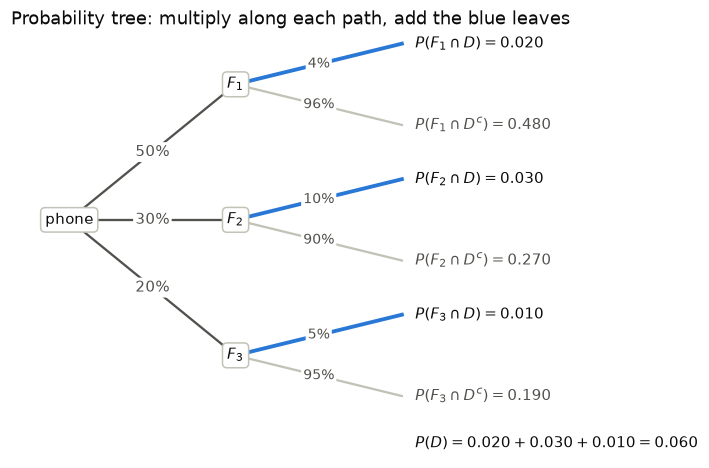

In [4]:
def draw_tree(ax, prior, p_def):
    # Level 1: factory, labeled P(F_i). Level 2: D or D^c, labeled P(. | F_i).
    # Each leaf shows its path product. Defective paths are blue.
    node = dict(boxstyle="round,pad=0.3", fc="white", ec=FAINT)
    tag = dict(boxstyle="round,pad=0.15", fc="white", ec="none")
    ax.text(0, 0, "phone", ha="center", va="center", color=INK, bbox=node, zorder=3)
    for i, (f, y) in enumerate(zip(prior, [2.0, 0.0, -2.0]), start=1):
        ax.plot([0, 1], [0, y], color=MUTED, lw=1.5, zorder=1)
        ax.text(0.5, y / 2, f"{float(prior[f]):.0%}", ha="center", va="center", color=MUTED, bbox=tag, zorder=2)
        ax.text(1, y, f"$F_{i}$", ha="center", va="center", color=INK, bbox=node, zorder=3)
        for hot, dy, p in [(True, 0.6, p_def[f]), (False, -0.6, 1 - p_def[f])]:
            ax.plot([1, 2], [y, y + dy], color=BLUE if hot else FAINT, lw=2.5 if hot else 1.5, zorder=1)
            ax.text(1.5, y + dy / 2, f"{float(p):.0%}", ha="center", va="center",
                    color=MUTED, bbox=tag, fontsize=9, zorder=2)
            leaf = "D" if hot else "D^c"
            ax.text(2.08, y + dy, rf"$P(F_{i} \cap {leaf}) = {float(prior[f] * p):.3f}$",
                    ha="left", va="center", color=INK if hot else MUTED)
    ax.set_xlim(-0.35, 3.75)
    ax.set_ylim(-3.5, 2.75)
    ax.set_axis_off()


fig, ax = plt.subplots(figsize=(8, 5))
draw_tree(ax, prior, p_def)
ax.text(2.08, -3.3, r"$P(D) = 0.020 + 0.030 + 0.010 = 0.060$", ha="left", va="center", color=INK)
ax.set_title("Probability tree: multiply along each path, add the blue leaves", color=INK, loc="left")
plt.show()

**Monte Carlo check.** Simulate a million phones: pick a factory with the given shares, then make the phone defective with that factory's rate. The fraction of defective phones should be close to 0.06.

In [5]:
N_PHONES = 1_000_000
factory = rng.choice(3, size=N_PHONES, p=[0.5, 0.3, 0.2])               # 0, 1, 2 stand for F1, F2, F3
defective = rng.random(N_PHONES) < np.array([0.04, 0.10, 0.05])[factory]
print(f"P(D): simulated {defective.mean():.4f}   exact {float(P_D):.4f}")

P(D): simulated 0.0599   exact 0.0600


## 3. Bayes' rule (slides 37-38)

**Intuition.** Conditional probabilities often arrive in the "wrong" direction. Data are usually collected from cause to effect: a factory's defect rate is $P(\text{defective} \mid \text{factory})$. After the fact we see the effect and ask about the cause: $P(\text{factory} \mid \text{defective})$. Bayes' rule runs the conditioning backward. It turns $P(F \mid E)$ into $P(E \mid F)$, using a bit more information: $P(E)$ and $P(F)$.

**Formal statement.** For events $E, F$ with $P(F) > 0$,

$$P(E \mid F) = \frac{P(E)\,P(F \mid E)}{P(F)}.$$

**Proof.** Write the intersection two ways using the definition of conditional probability, $P(E \cap F) = P(F)\,P(E \mid F) = P(E)\,P(F \mid E)$, and divide by $P(F)$.

The denominator $P(F)$ is rarely given directly. Compute it by total probability over a partition $E_1, \dots, E_k$:

$$P(E_i \mid F) = \frac{P(E_i)\,P(F \mid E_i)}{\sum_{j=1}^{k} P(E_j)\,P(F \mid E_j)}.$$

Vocabulary: $P(E_i)$ is the **prior** (belief before seeing $F$), $P(F \mid E_i)$ is the **likelihood** (how well $E_i$ explains $F$), and $P(E_i \mid F)$ is the **posterior** (belief after seeing $F$). In words: posterior is proportional to prior times likelihood.

**Check on two dice.** With $E$ = "first die even" and $F$ = "sum is 8" from Section 1,

$$P(E \mid F) = \frac{P(E)\,P(F \mid E)}{P(F)} = \frac{\frac{1}{2} \cdot \frac{1}{6}}{5/36} = \frac{3}{5}.$$

Directly: of the 5 outcomes with sum 8, three, namely $(2,6), (4,4), (6,2)$, have an even first die.

In [6]:
show("Bayes  P(E | F)", P(first_even) * P_given(sum_is_8, first_even) / P(sum_is_8))
show("direct P(E | F)", P_given(first_even, sum_is_8))

Bayes  P(E | F): 3/5 = 0.600000
direct P(E | F): 3/5 = 0.600000


## 4. Example: which factory made the defective phone? (slide 39)

**Question.** You buy a phone and it turns out to be defective. What is the probability that it was made by each factory?

**Step by step.** Apply Bayes' rule with the partition $F_1, F_2, F_3$ and $P(D) = 0.06$ from Section 2:

$$P(F_1 \mid D) = \frac{P(F_1)\,P(D \mid F_1)}{P(D)} = \frac{0.5 \cdot 0.04}{0.06} = \frac{0.02}{0.06} = \frac{1}{3},$$

$$P(F_2 \mid D) = \frac{0.3 \cdot 0.1}{0.06} = \frac{0.03}{0.06} = \frac{1}{2}, \qquad P(F_3 \mid D) = \frac{0.2 \cdot 0.05}{0.06} = \frac{0.01}{0.06} = \frac{1}{6}.$$

On the tree: keep only the blue leaves (2%, 3%, and 1% of all phones) and rescale them so they add to 1. Each posterior is that leaf's share of the 6%.

**Three sanity checks.**

1. **They add to 1:** $\frac{1}{3} + \frac{1}{2} + \frac{1}{6} = 1$, as they must, since a defective phone came from some factory.
2. **They are proportional to the joint probabilities** $P(F_i \cap D) = 2\%, 3\%, 1\%$, which total 6%: the posteriors are $2/6, 3/6, 1/6$.
3. **$P(F_i \mid D)$ grows with both $P(F_i)$ and $P(D \mid F_i)$.** A bigger factory makes more phones of every kind, and a sloppier factory makes more defects. Factory 2 makes only 30% of the phones but half of the defective ones, because its defect rate is the highest.

In [7]:
posterior = {f: joint[f] / P_D for f in factories}
for f in factories:
    show(f"P({f} | D)", posterior[f])
assert sum(posterior.values()) == 1

P(F1 | D): 1/3 = 0.333333
P(F2 | D): 1/2 = 0.500000
P(F3 | D): 1/6 = 0.166667


**Monte Carlo check.** Among the simulated defective phones from Section 2, count the share made by each factory.

In [8]:
for i, f in enumerate(factories):
    print(f"P({f} | D): simulated {np.mean(factory[defective] == i):.4f}   exact {float(posterior[f]):.4f}")

P(F1 | D): simulated 0.3351   exact 0.3333
P(F2 | D): simulated 0.4976   exact 0.5000
P(F3 | D): simulated 0.1673   exact 0.1667


The chart compares beliefs before and after seeing the defect. Learning that the phone is defective moves probability away from the large but careful factory 1 and toward factory 2.

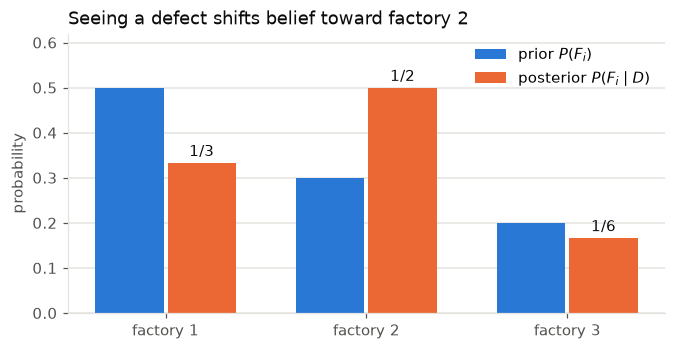

In [9]:
x = np.arange(3)
w = 0.34
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(x - w / 2 - 0.01, [float(prior[f]) for f in factories], width=w, color=BLUE, label=r"prior $P(F_i)$")
ax.bar(x + w / 2 + 0.01, [float(posterior[f]) for f in factories], width=w, color=ORANGE,
       label=r"posterior $P(F_i \mid D)$")
for xi, f in zip(x, factories):
    ax.text(xi + w / 2 + 0.01, float(posterior[f]) + 0.015, str(posterior[f]), ha="center", color=INK)
ax.set_xticks(x, ["factory 1", "factory 2", "factory 3"])
ax.grid(axis="x", visible=False)
ax.set(ylim=(0, 0.62), ylabel="probability")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Seeing a defect shifts belief toward factory 2", color=INK, loc="left")
plt.show()

## 5. Random variables (slide 40)

**Intuition.** A random variable is a random experiment whose outcome is a number. Most experiments we care about produce numbers: a die roll, a count of heads, the number of defective phones in a shipment, a waiting time. Even when the raw outcome is not a number (a poker hand), we usually care about a number attached to it (how many aces it holds). Working with numbers has four advantages:

- **Specify:** a distribution can be given by a table or a formula over numbers.
- **Visualize:** probabilities can be plotted against the number line.
- **Functions:** new random variables come for free, such as $X^2$, $|X - 1|$, or $2^X$.
- **Operations:** random variables can be added, averaged, and compared, as in $X + Y$, and summarized by numbers such as the mean.

**Formal definition.** A random variable $X$ on a sample space $\Omega$ assigns a real number $X(\omega)$ to each outcome $\omega \in \Omega$. Uppercase $X$ denotes the random variable and lowercase $x$ a particular value. The event "$X = x$" is the set $\lbrace \omega : X(\omega) = x \rbrace$.

There are two main **types**. A *discrete* random variable takes finitely or countably many values, and is the subject of this session. A *continuous* random variable spreads its probability over an interval; it appears in Session 5.

**Example.** Roll two dice, so $\Omega$ is the 36 equally likely ordered pairs. Many random variables live on the same $\Omega$, for example the sum $S(a, b) = a + b$ and the maximum $M(a, b) = \max(a, b)$. The event $\lbrace S = 4 \rbrace = \lbrace (1,3), (2,2), (3,1) \rbrace$ has probability $3/36$.

In [10]:
S = lambda w: w[0] + w[1]   # sum of the two dice
M = lambda w: max(w)        # larger of the two dice

for w in [(1, 3), (2, 2), (6, 5)]:
    print(f"outcome {w}:  S = {S(w):2d},  M = {M(w)}")
print("event {S = 4} =", [w for w in dice if S(w) == 4])
show("P(S = 4)", P(lambda w: S(w) == 4))

outcome (1, 3):  S =  4,  M = 3
outcome (2, 2):  S =  4,  M = 2
outcome (6, 5):  S = 11,  M = 6
event {S = 4} = [(1, 3), (2, 2), (3, 1)]
P(S = 4): 1/12 = 0.083333


## 6. PMF and CDF (slide 41)

**Intuition.** There are two standard ways to describe the distribution of a discrete random variable. The PMF answers "how likely is *exactly* $x$?"; the CDF answers "how likely is *at most* $x$?". Each one determines the other.

**Formal definitions.**

- The **probability mass function** (PMF) is $p(x) = P(X = x)$, the probability *of* $x$. It satisfies $p(x) \ge 0$ and $\sum_x p(x) = 1$.
- The **cumulative distribution function** (CDF) is

$$F(x) = P(X \le x) = P\big(X \in (-\infty, x]\big) = \sum_{u \le x} p(u),$$

the probability *up to* $x$. Even when $X$ is discrete, $F$ is defined for every real $x$.

For a discrete $X$, the CDF is a staircase:

- it is nondecreasing, tends to 0 as $x \to -\infty$ and to 1 as $x \to \infty$;
- it is flat between consecutive values of $X$ and jumps by exactly $p(x)$ at each value $x$;
- at a jump, $F(x)$ already includes the jump (the function is right-continuous), while $P(X < x)$ is the level just to the left;
- interval probabilities are differences: $P(a < X \le b) = F(b) - F(a)$.

**Example (sum of two dice).** Go from the PMF to the CDF with running sums, evaluate $F$ at points that are not values of $S$, and come back to the PMF from the jumps.

In [11]:
def pmf_of(rv, space=dice):
    # PMF of a random variable on an equiprobable space, as {value: probability}.
    counts = Counter(rv(w) for w in space)
    return {x: Fraction(c, len(space)) for x, c in sorted(counts.items())}


def cdf(pmf, x):
    return sum((p for v, p in pmf.items() if v <= x), Fraction(0))


pmf_S = pmf_of(S)
print("PMF of S:", {x: str(p) for x, p in pmf_S.items()})
for x in [-3, 2, 4, 4.5, 6.99, 7, 100]:
    print(f"F({x}) = {cdf(pmf_S, x)}")

PMF of S: {2: '1/36', 3: '1/18', 4: '1/12', 5: '1/9', 6: '5/36', 7: '1/6', 8: '5/36', 9: '1/9', 10: '1/12', 11: '1/18', 12: '1/36'}
F(-3) = 0
F(2) = 1/36
F(4) = 1/6
F(4.5) = 1/6
F(6.99) = 5/12
F(7) = 7/12
F(100) = 1


In [12]:
# Back from the CDF to the PMF: S has integer values, so the jump at x is F(x) - F(x - 1).
jumps = {x: cdf(pmf_S, x) - cdf(pmf_S, x - 1) for x in range(2, 13)}
assert jumps == pmf_S
show("P(4 < S <= 7) = F(7) - F(4)", cdf(pmf_S, 7) - cdf(pmf_S, 4))
show("P(S < 7) = F(6)            ", cdf(pmf_S, 6))

P(4 < S <= 7) = F(7) - F(4): 5/12 = 0.416667
P(S < 7) = F(6)            : 5/12 = 0.416667


## 7. Example: Bernoulli(0.7) PMF and CDF (slide 42)

**Intuition.** The simplest random variable takes only the values 0 and 1. It models any yes/no outcome: success or failure, defective or not, heads or tails. The Bernoulli variable $B_{0.7}$ equals 1 with probability 0.7.

**PMF and CDF, step by step.**

$$p(x) = \begin{cases} 0.3 & x = 0, \\ 0.7 & x = 1, \\ 0 & x \ne 0, 1, \end{cases} \qquad F(x) = \begin{cases} 0 & x < 0, \\ 0.3 & 0 \le x < 1, \\ 1 & 1 \le x. \end{cases}$$

- To the left of 0 there is no mass yet, so $F = 0$.
- At 0, $F$ jumps by $p(0) = 0.3$ and stays flat until 1.
- At 1, $F$ jumps by $p(1) = 0.7$ up to 1, and stays there.

So $F(-5) = 0$, $F(0.5) = 0.3$, and $F(17) = 1$: the CDF is defined everywhere even though $X$ has only two values. In the plot, a filled dot marks the value $F$ takes at a jump and an open dot marks the level just to the left.

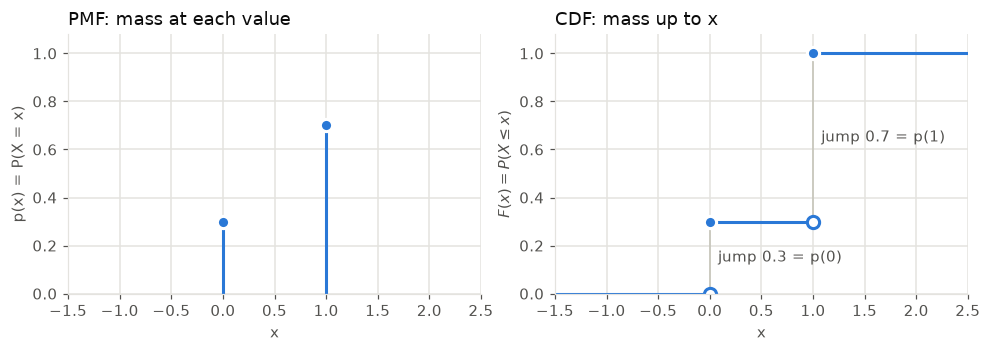

In [13]:
p = Fraction(7, 10)
pmf_B = {0: 1 - p, 1: p}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.3))
xs, ps = list(pmf_B), [float(q) for q in pmf_B.values()]
ax1.vlines(xs, 0, ps, color=BLUE, lw=2)
ax1.plot(xs, ps, "o", color=BLUE, ms=8, mec="white", mew=2)
ax1.set(xlim=(-1.5, 2.5), ylim=(0, 1.08), xlabel="x", ylabel="p(x) = P(X = x)")
ax1.set_title("PMF: mass at each value", color=INK, loc="left")

for a, b, level in [(-1.5, 0, 0), (0, 1, 0.3), (1, 2.5, 1)]:
    ax2.plot([a, b], [level, level], color=BLUE, lw=2)
ax2.vlines([0, 1], [0, 0.3], [0.3, 1], color=FAINT, lw=1)
ax2.plot([0, 1], [0, 0.3], "o", color="white", ms=8, mec=BLUE, mew=2)   # level just to the left
ax2.plot([0, 1], [0.3, 1], "o", color=BLUE, ms=8, mec="white", mew=2)   # F includes the jump
ax2.text(0.08, 0.15, "jump 0.3 = p(0)", va="center", color=MUTED)
ax2.text(1.08, 0.65, "jump 0.7 = p(1)", va="center", color=MUTED)
ax2.set(xlim=(-1.5, 2.5), ylim=(0, 1.08), xlabel="x", ylabel=r"$F(x) = P(X \leq x)$")
ax2.set_title("CDF: mass up to x", color=INK, loc="left")
plt.tight_layout()
plt.show()

**Monte Carlo check.** Draw 100,000 samples of $B_{0.7}$ and compare the fraction of samples at most $t$ with $F(t)$, including points between the values.

In [14]:
samples = (rng.random(100_000) < 0.7).astype(int)
for t in [-0.5, 0, 0.5, 1, 2]:
    print(f"F({t:4}): simulated {np.mean(samples <= t):.4f}   exact {float(cdf(pmf_B, t)):.4f}")

F(-0.5): simulated 0.0000   exact 0.0000
F(   0): simulated 0.2994   exact 0.3000
F( 0.5): simulated 0.2994   exact 0.3000
F(   1): simulated 1.0000   exact 1.0000
F(   2): simulated 1.0000   exact 1.0000


## 8. Expectation (slide 43)

**Intuition.** Draw a large number $n$ of samples of $X$. Each value $x$ shows up about $p(x) \cdot n$ times, so the average of the samples is about

$$\frac{\sum_x \big[p(x) \cdot n\big] \cdot x}{n} = \sum_x p(x) \cdot x.$$

The $n$ cancels: the long-run average depends only on the distribution. That number is the expectation.

**Formal definition.** The **expectation** (or **mean**) of a discrete random variable $X$ is

$$E(X) = \sum_x x \, p(x).$$

It is also written $E[X]$, $EX$, $\mu_X$, or just $\mu$. Although $X$ is random, $E[X]$ is **not**: it is a fixed number computed from the distribution alone. Even so, it tells you where the average of many independent samples will land. (The law of large numbers, later in the course, makes this precise.)

**Example (sum of two dice), step by step.** $E[S] = \sum_{s=2}^{12} s \, p(s) = \frac{2 \cdot 1 + 3 \cdot 2 + \cdots + 12 \cdot 1}{36} = \frac{252}{36} = 7$. To see the intuition at work, roll the dice $n = 36{,}000$ times. Each value $s$ should appear about $p(s) \cdot n$ times, and the sample average should be close to 7.

In [15]:
def E(pmf):
    return sum(x * p for x, p in pmf.items())


show("E[S]", E(pmf_S))

n = 36_000
rolls = rng.integers(1, 7, size=(n, 2)).sum(axis=1)
counts = Counter(rolls.tolist())
print(" s   count   p(s)*n")
for s, ps in pmf_S.items():
    print(f"{s:2d}  {counts[s]:6d}  {float(ps) * n:7.0f}")
print(f"sample average {rolls.mean():.4f}   E[S] = {float(E(pmf_S))}")

E[S]: 7 = 7.000000
 s   count   p(s)*n
 2    1008     1000
 3    2051     2000
 4    2966     3000
 5    3934     4000
 6    5059     5000
 7    5902     6000
 8    4992     5000
 9    4014     4000
10    3056     3000
11    1978     2000
12    1040     1000
sample average 7.0064   E[S] = 7.0


The sample average itself is random, but it wanders less and less as $n$ grows, while $E[S] = 7$ stays fixed.

In [16]:
for n in [10, 100, 10_000, 1_000_000]:
    average = rng.integers(1, 7, size=(n, 2)).sum(axis=1).mean()
    print(f"n = {n:>9,}: sample average {average:.4f}")

n =        10: sample average 7.3000
n =       100: sample average 6.4000
n =    10,000: sample average 7.0071
n = 1,000,000: sample average 6.9972


## 9. Bernoulli expectation (slide 44)

**Formal definition.** For $0 \le p \le 1$, the Bernoulli distribution $B_p$ has two values:

| Value | 0 | 1 |
|---|---|---|
| Probability | $1 - p$ | $p$ |

The probability $1 - p$ is often written $q$ or $\bar{p}$.

**Expectation, step by step.**

$$E[X] = \sum_x x \, p(x) = (1 - p) \cdot 0 + p \cdot 1 = p.$$

So the mean of a 0/1 variable is the probability that it equals 1. For $X \sim B_{0.7}$, $E[X] = 0.7$. This small fact is the engine of the indicator method in Section 17. (Session 5 studies Bernoulli and related distributions as a family.)

In [17]:
for q in [Fraction(0), Fraction(3, 10), Fraction(7, 10), Fraction(1)]:
    show(f"p = {q}: E[B_p]", E({0: 1 - q, 1: q}))
print(f"B_0.7 sample mean: {samples.mean():.4f}   exact 0.7")

p = 0: E[B_p]: 0 = 0.000000
p = 3/10: E[B_p]: 3/10 = 0.300000
p = 7/10: E[B_p]: 7/10 = 0.700000
p = 1: E[B_p]: 1 = 1.000000
B_0.7 sample mean: 0.7006   exact 0.7


## 10. Example: three coins (slide 45)

**Setup.** Toss a coin 3 times and let $X$ be the number of heads. Group the 8 equally likely outcomes by their value of $X$:

| $x$ | outcomes | $p(x)$ |
|---|---|---|
| 0 | TTT | 1/8 |
| 1 | TTH, THT, HTT | 3/8 |
| 2 | THH, HTH, HHT | 3/8 |
| 3 | HHH | 1/8 |

**Expectation, step by step.**

$$E[X] = \tfrac{1}{8} \cdot 0 + \tfrac{3}{8} \cdot 1 + \tfrac{3}{8} \cdot 2 + \tfrac{1}{8} \cdot 3 = \tfrac{12}{8} = 1.5.$$

The number of heads ranges from 0 to 3 and is 1.5 on average, a value it can never take. That is fine: the mean is a long-run average, not a typical outcome.

**Symmetry shortcut.** Swapping heads and tails turns $X$ into $3 - X$ without changing any probability, so $p(x) = p(3 - x)$: the PMF is a mirror image around 1.5. The mass balances at the center of symmetry, so $E[X] = 1.5$ with no arithmetic.

In [18]:
coins = list(product("HT", repeat=3))
X_heads = lambda w: w.count("H")
pmf_X = pmf_of(X_heads, coins)
for x, px in pmf_X.items():
    print(x, ["".join(w) for w in coins if X_heads(w) == x], px)
show("E[X]", E(pmf_X))
assert all(pmf_X[x] == pmf_X[3 - x] for x in pmf_X)   # PMF symmetric around 3/2
print(f"simulated mean: {(rng.random((100_000, 3)) < 0.5).sum(axis=1).mean():.4f}")

0 ['TTT'] 1/8
1 ['HTT', 'THT', 'TTH'] 3/8
2 ['HHT', 'HTH', 'THH'] 3/8
3 ['HHH'] 1/8
E[X]: 3/2 = 1.500000
simulated mean: 1.4962


## 11. Expectation via tail sums (slide 46)

**Intuition.** Let $X$ take values in $\mathbb{N} = \lbrace 0, 1, 2, \dots \rbrace$ and write $p_i = P(X = i)$. The definition $E[X] = \sum_i i \, p_i = p_1 + 2p_2 + 3p_3 + \cdots$ uses $p_1$ once, $p_2$ twice, $p_3$ three times, and so on. Stack those copies in a triangle, with column $i$ holding $i$ copies of $p_i$:

```
row 3:              p3   p4   ...    =  P(X >= 3)
row 2:         p2   p3   p4   ...    =  P(X >= 2)
row 1:    p1   p2   p3   p4   ...    =  P(X >= 1)
         ---  ---  ---  ---
columns:  1p1  2p2  3p3  4p4  ...    =  E[X]
```

Adding by columns gives the definition. Adding by rows instead gives $(p_1 + p_2 + \cdots) + (p_2 + p_3 + \cdots) + \cdots = P(X \ge 1) + P(X \ge 2) + \cdots$.

**Formal statement.** If $X$ takes values in $\lbrace 0, 1, 2, \dots \rbrace$, then

$$E[X] = \sum_{i=1}^{\infty} P(X \ge i).$$

**Proof.** $\sum_{i \ge 1} P(X \ge i) = \sum_{i \ge 1} \sum_{k \ge i} p_k = \sum_{k \ge 1} \sum_{i=1}^{k} p_k = \sum_{k \ge 1} k \, p_k = E[X]$. Swapping the order of summation is allowed because every term is nonnegative.

The function $i \mapsto P(X \ge i)$ is the "right" CDF: it accumulates probability from the right instead of the left, and $P(X \ge i) = 1 - F(i - 1)$.

- It takes about as many additions as the definition, and **no multiplications**.
- It shines when tails are easier than point probabilities: in waiting problems, $X \ge i$ just says "nothing happened in the first $i - 1$ steps".
- It needs nonnegative integer values, and the sum starts at $i = 1$.

**Example (three coins).** $P(X \ge 1) = 7/8$, $P(X \ge 2) = 4/8$, $P(X \ge 3) = 1/8$, which add up to $12/8 = 1.5$, as in Section 10.

In [19]:
def E_tail(pmf):
    # E[X] = sum over i >= 1 of P(X >= i), for X with values in {0, 1, 2, ...}.
    return sum(sum(p for x, p in pmf.items() if x >= i) for i in range(1, max(pmf) + 1))


print("three coins tails:", [str(sum(p for x, p in pmf_X.items() if x >= i)) for i in (1, 2, 3)])
for name, pmf in [("three coins X ", pmf_X), ("two-dice sum S", pmf_S)]:
    print(f"{name}: definition {E(pmf)}   tail sum {E_tail(pmf)}")

three coins tails: ['7/8', '1/2', '1/8']
three coins X : definition 3/2   tail sum 3/2
two-dice sum S: definition 7   tail sum 7


## 12. Example: waiting for the queen of hearts (slide 47)

**Setup.** Jim is choosy: the only card he will stop for is the queen of hearts. He deals cards one at a time, without replacement, from a shuffled deck until the queen of hearts appears. Let $X$ be the number of cards dealt, including the queen. The queen is equally likely to sit in any of the 52 positions, so $X$ is uniform on $\lbrace 1, \dots, 52 \rbrace$.

**Three ways to find $E[X]$.**

1. **Uniform average:** $E[X] = \dfrac{1 + 2 + \cdots + 52}{52} = \dfrac{52 \cdot 53}{2 \cdot 52} = \dfrac{53}{2}$.
2. **Symmetry:** the PMF is flat on $1, \dots, 52$, so it balances at the midpoint $\dfrac{1 + 52}{2}$.
3. **Tail sums:** $X \ge i$ means the queen is not among the first $i - 1$ cards, so $P(X \ge i) = \dfrac{52 - (i - 1)}{52} = \dfrac{53 - i}{52}$ and

$$E[X] = \frac{52}{52} + \frac{51}{52} + \cdots + \frac{1}{52} = 26.5.$$

All three give 26.5.

In [20]:
N_CARDS = 52
by_uniform = Fraction(sum(range(1, N_CARDS + 1)), N_CARDS)
by_symmetry = Fraction(1 + N_CARDS, 2)
by_tails = sum(Fraction(N_CARDS + 1 - i, N_CARDS) for i in range(1, N_CARDS + 1))
show("uniform average", by_uniform)
show("symmetry       ", by_symmetry)
show("tail sums      ", by_tails)

uniform average: 53/2 = 26.500000
symmetry       : 53/2 = 26.500000
tail sums      : 53/2 = 26.500000


**Monte Carlo check.** Shuffle 100,000 decks and record where the queen of hearts lands. Label the two red queens as cards 0 (hearts) and 1 (diamonds); the same decks are reused in the next section.

In [21]:
N_SIM = 100_000
decks = rng.permuted(np.tile(np.arange(N_CARDS), (N_SIM, 1)), axis=1)   # one shuffled deck per row
QH, QD = 0, 1                                                          # queen of hearts, queen of diamonds
pos_QH = np.argmax(decks == QH, axis=1) + 1                            # positions counted from 1
print(f"queen of hearts: simulated mean {pos_QH.mean():.3f}   exact {float(by_tails)}")

queen of hearts: simulated mean 26.559   exact 26.5


## 13. Example: waiting for any red queen (slide 48)

**Setup.** Jim relaxes: now either red queen (hearts or diamonds) will do, and he stops at whichever comes first. Let $X$ be the position of the first of the two red queens.

**Why the first two methods fail.** $P(X = 52) = 0$, because both red queens cannot sit in position 52, while $P(X = 1) = 2/52 > 0$. So $X$ is neither uniform nor symmetric, and neither the uniform average nor the symmetry argument applies.

**Tail sums still work.** $X \ge i$ means both red queens sit in positions $i, \dots, 52$, a block of $53 - i$ positions. The pair of red-queen positions is equally likely to be any of the $\binom{52}{2}$ pairs, so

$$P(X \ge i) = \frac{\binom{53 - i}{2}}{\binom{52}{2}}, \qquad i = 1, \dots, 52.$$

For $i = 1$ both red queens are somewhere in the last 52 cards, giving $\binom{52}{2}$; for $i = 2$ they are in the last 51; and so on down to $\binom{2}{2}$ for $i = 51$ (both in the last 2 cards) and 0 for $i = 52$. Therefore

$$E[X] = \frac{\binom{52}{2} + \binom{51}{2} + \cdots + \binom{2}{2}}{\binom{52}{2}} = \frac{\binom{53}{3}}{\binom{52}{2}} = \frac{53 \cdot 52 \cdot 51 / 6}{52 \cdot 51 / 2} = \frac{53}{3} \approx 17.67.$$

The middle step is the **hockey-stick identity** $\sum_{i=2}^{n} \binom{i}{2} = \binom{n+1}{3}$. Counting proof: to choose 3 numbers from $\lbrace 1, \dots, n+1 \rbrace$, first fix the largest one, say $i + 1$; the other two then come from $\lbrace 1, \dots, i \rbrace$ in $\binom{i}{2}$ ways.

A more elegant symmetry argument, developed later, gives $\frac{n+1}{k+1}$ for the first of $k$ special cards in an $n$-card deck (see also Problem 10 in the exercises).

In [22]:
tails_red = [Fraction(comb(53 - i, 2), comb(52, 2)) for i in range(1, 53)]
show("E[X] by tail sums  ", sum(tails_red))
show("C(53, 3) / C(52, 2)", Fraction(comb(53, 3), comb(52, 2)))
assert all(sum(comb(i, 2) for i in range(2, n + 1)) == comb(n + 1, 3) for n in range(2, 100))   # hockey stick

first = [min(pair) + 1 for pair in combinations(range(52), 2)]   # every equally likely pair of positions
show("brute force over all position pairs", Fraction(sum(first), len(first)))

pos_red = np.minimum(pos_QH, np.argmax(decks == QD, axis=1) + 1)
print(f"first red queen: simulated mean {pos_red.mean():.3f}   exact {53 / 3:.3f}")

E[X] by tail sums  : 53/3 = 17.666667
C(53, 3) / C(52, 2): 53/3 = 17.666667
brute force over all position pairs: 53/3 = 17.666667
first red queen: simulated mean 17.703   exact 17.667


The plot puts the two waiting times side by side. On the left, the PMF of the first red queen decreases steadily, which is why the uniform shortcut fails. On the right, the bar heights are the tail probabilities, and by the tail-sum formula they add up to the expectation.

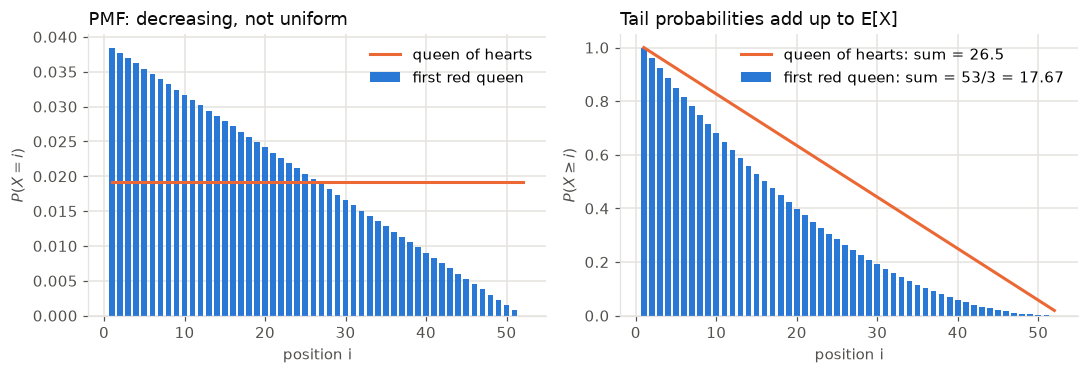

In [23]:
i = np.arange(1, 53)
pmf_red = (52 - i) / comb(52, 2)                                  # P(X = i) = P(X >= i) - P(X >= i + 1)
tail_red = np.array([comb(53 - k, 2) for k in i]) / comb(52, 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.bar(i, pmf_red, width=0.7, color=BLUE, label="first red queen")
ax1.plot(i, np.full(52, 1 / 52), color=ORANGE, lw=2, label="queen of hearts")
ax1.set(xlabel="position i", ylabel=r"$P(X = i)$")
ax1.set_title("PMF: decreasing, not uniform", color=INK, loc="left")
ax1.legend(frameon=False)

ax2.bar(i, tail_red, width=0.7, color=BLUE, label="first red queen: sum = 53/3 = 17.67")
ax2.plot(i, (53 - i) / 52, color=ORANGE, lw=2, label="queen of hearts: sum = 26.5")
ax2.set(xlabel="position i", ylabel=r"$P(X \geq i)$")
ax2.set_title("Tail probabilities add up to E[X]", color=INK, loc="left")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

## 14. LOTUS: expectations of functions (slide 49)

**Intuition.** Often the quantity of interest is a function of a random variable: a squared error, the cost of a random demand. To find $E[g(X)]$ there are two routes:

- **Two steps:** first find the PMF of $Y = g(X)$, then use the definition, $E[Y] = \sum_y y \, P(Y = y)$.
- **One step:** weight each $g(x)$ by $p(x)$ directly.

**Formal statement (Law of the Unconscious Statistician).**

$$E[g(X)] = \sum_x g(x) \, p(x).$$

The name is a joke: it feels so natural that people use it without noticing that it is a theorem and not the definition of $E[g(X)]$.

**Why it works.** $P(Y = y) = \sum_{x : g(x) = y} p(x)$, so

$$\sum_y y \, P(Y = y) = \sum_y \sum_{x : g(x) = y} g(x) \, p(x) = \sum_x g(x) \, p(x).$$

The one-step sum is the two-step sum with its terms regrouped.

**Consequence: affine maps.** With $g(x) = ax + b$,

$$E[aX + b] = \sum_x (ax + b) \, p(x) = a \sum_x x \, p(x) + b \sum_x p(x) = a \, E[X] + b.$$

Scaling and shifting pass straight through the expectation. For the three coins, $E[2X - 1] = 2 \cdot 1.5 - 1 = 2$.

In [24]:
def pmf_of_g(pmf, g):
    # Two-step route: the PMF of Y = g(X), collecting the x values that share a y.
    out = {}
    for x, px in pmf.items():
        out[g(x)] = out.get(g(x), 0) + px
    return dict(sorted(out.items()))


def E_g(pmf, g):
    # One-step route (LOTUS).
    return sum(g(x) * px for x, px in pmf.items())


a, b = 2, -1
show("E[2X - 1] by LOTUS     ", E_g(pmf_X, lambda x: a * x + b))
show("E[2X - 1] by two steps ", E(pmf_of_g(pmf_X, lambda x: a * x + b)))
show("a E[X] + b             ", a * E(pmf_X) + b)

E[2X - 1] by LOTUS     : 2 = 2.000000
E[2X - 1] by two steps : 2 = 2.000000
a E[X] + b             : 2 = 2.000000


## 15. Example: expectation of a square (slide 50)

**Setup.** $X$ is uniform on $\lbrace -2, -1, 0, 1, 2 \rbrace$, each value with probability $1/5$, and $Y = X^2$.

**Two steps.** Find the PMF of $Y$ by collecting the values of $X$ that give each $y$:

- $P(Y = 0) = P(X^2 = 0) = P(X = 0) = 1/5$;
- $P(Y = 1) = P(X^2 = 1) = P(X \in \lbrace -1, 1 \rbrace) = 2/5$;
- $P(Y = 4) = P(X^2 = 4) = P(X \in \lbrace -2, 2 \rbrace) = 2/5$.

Then $E[Y] = \frac{1}{5} \cdot 0 + \frac{2}{5} \cdot 1 + \frac{2}{5} \cdot 4 = \frac{10}{5} = 2$.

**One step (LOTUS).**

$$E[Y] = \tfrac{1}{5}(-2)^2 + \tfrac{1}{5}(-1)^2 + \tfrac{1}{5} \cdot 0^2 + \tfrac{1}{5} \cdot 1^2 + \tfrac{1}{5} \cdot 2^2 = \tfrac{10}{5} = 2.$$

**Watch out.** $E[X] = 0$ by symmetry, so $(E[X])^2 = 0 \ne 2 = E[X^2]$. Squaring does not pass through the expectation; only affine maps do. (The gap $E[X^2] - (E[X])^2$ is the variance, the topic of Session 4.)

In [25]:
pmf_U = {x: Fraction(1, 5) for x in [-2, -1, 0, 1, 2]}
square = lambda x: x * x

pmf_Y = pmf_of_g(pmf_U, square)
print("PMF of Y = X^2:", {y: str(py) for y, py in pmf_Y.items()})
show("two steps  E[Y]", E(pmf_Y))
show("one step   E[Y]", E_g(pmf_U, square))
show("(E[X])^2       ", E(pmf_U) ** 2)

PMF of Y = X^2: {0: '1/5', 1: '2/5', 4: '2/5'}
two steps  E[Y]: 2 = 2.000000
one step   E[Y]: 2 = 2.000000
(E[X])^2       : 0 = 0.000000


## 16. Linearity of expectation (slide 51)

**Intuition.** The mean of a sum is the sum of the means, no matter how the variables are related.

**Formal statement.** For random variables $X, Y$ on the same sample space and constants $a, b, c$,

$$E[aX + bY + c] = a \, E[X] + b \, E[Y] + c,$$

and similarly for more variables: $E\big[\sum_i a_i X_i\big] = \sum_i a_i \, E[X_i]$.

**Why it works.** Grouping outcomes by the value of $X$ shows that $E[X] = \sum_{\omega} X(\omega) \, P(\omega)$ (for a discrete $\Omega$). Then

$$E[aX + bY + c] = \sum_{\omega} \big(aX(\omega) + bY(\omega) + c\big) P(\omega) = a \sum_{\omega} X(\omega) P(\omega) + b \sum_{\omega} Y(\omega) P(\omega) + c.$$

Nothing in this argument uses independence.

**Example (two dice).** Let $D_1, D_2$ be the two dice, $S = D_1 + D_2$, and $M$ the maximum.

- $E[S] = E[D_1] + E[D_2] = \frac{7}{2} + \frac{7}{2} = 7$, matching Section 8 without the 11-term sum.
- $D_1$ and $M$ are strongly dependent ($M \ge D_1$ always), yet $E[3D_1 - 2M + 5] = 3E[D_1] - 2E[M] + 5$ still holds.
- Products are different: $E[D_1 M] \ne E[D_1] \, E[M]$ here. Products of dependent variables are the subject of covariance in Session 4.

In [26]:
def E_omega(rv, space=dice):
    # Expectation as an average over equally likely outcomes.
    return Fraction(sum(rv(w) for w in space), len(space))


D1 = lambda w: w[0]
D2 = lambda w: w[1]
show("E[D1] + E[D2]     ", E_omega(D1) + E_omega(D2))
show("E[S]              ", E_omega(S))
show("E[3 D1 - 2 M + 5] ", E_omega(lambda w: 3 * D1(w) - 2 * M(w) + 5))
show("3E[D1] - 2E[M] + 5", 3 * E_omega(D1) - 2 * E_omega(M) + 5)
show("E[D1 M]           ", E_omega(lambda w: D1(w) * M(w)))
show("E[D1] E[M]        ", E_omega(D1) * E_omega(M))

E[D1] + E[D2]     : 7 = 7.000000
E[S]              : 7 = 7.000000
E[3 D1 - 2 M + 5] : 59/9 = 6.555556
3E[D1] - 2E[M] + 5: 59/9 = 6.555556
E[D1 M]           : 154/9 = 17.111111
E[D1] E[M]        : 1127/72 = 15.652778


## 17. The indicator method (slide 52)

**Intuition.** Some expectations are hard because the distribution is hard to find. When $X$ *counts* how many of several things happen, write it as a sum of 0/1 variables, one per thing. Each piece has an easy expectation (a probability), and linearity adds them up. The distribution of $X$ is never needed.

**Formal definitions.** The **indicator** of an event $A$ is

$$I_A = \begin{cases} 1 & \text{if } A \text{ occurs}, \\ 0 & \text{otherwise}. \end{cases}$$

It is Bernoulli with parameter $P(A)$, so $E[I_A] = P(A)$ by Section 9. If $X$ is the number of the events $A_1, \dots, A_m$ that occur, then $X = I_{A_1} + \cdots + I_{A_m}$ and by linearity

$$E[X] = \sum_{j=1}^{m} E[I_{A_j}] = \sum_{j=1}^{m} P(A_j).$$

The recipe: (1) split the count into indicators, (2) find each $P(A_j)$, often equal by symmetry, (3) add. The events may be dependent; linearity does not care.

**Example (three coins again).** Let $I_j = 1$ if toss $j$ is heads. Then $X = I_1 + I_2 + I_3$ and $E[X] = 3 \cdot \frac{1}{2} = \frac{3}{2}$, with no PMF table at all.

**Bonus: tail sums are an indicator argument.** For $X \in \lbrace 0, 1, 2, \dots \rbrace$, exactly $X$ of the indicators $I_{\lbrace X \ge 1 \rbrace}, I_{\lbrace X \ge 2 \rbrace}, \dots$ equal 1, so $X = \sum_{i \ge 1} I_{\lbrace X \ge i \rbrace}$. Taking expectations gives the formula of Section 11 in one line.

In [27]:
indicator_sum = sum(E_omega(lambda w, j=j: int(w[j] == "H"), coins) for j in range(3))
show("sum of E[I_j]", indicator_sum)
show("E[X] from PMF", E(pmf_X))
# Outcome by outcome, X equals the number of i >= 1 with X >= i.
assert all(X_heads(w) == sum(X_heads(w) >= i for i in range(1, 4)) for w in coins)

sum of E[I_j]: 3/2 = 1.500000
E[X] from PMF: 3/2 = 1.500000


## 18. Example: expected number of distinct birthdays (slides 53-54)

**Setup.** There are $n$ students. Each birthday is equally likely to be any of 365 days, independently. Let $D$ be the number of *distinct* birthdays. For example, with $n = 3$ and birthdays on days 1, 365, 1, we get $D = 2$. What is $E[D]$?

**The direct route gets messy.**

- $n = 1$: $D = 1$, so $E[D] = 1$.
- $n = 2$: $D = 1$ if the two share a birthday (probability $1/365$), otherwise 2:

$$E[D] = P(D = 1) \cdot 1 + P(D = 2) \cdot 2 = \frac{1}{365} \cdot 1 + \frac{364}{365} \cdot 2 = 2 - \frac{1}{365}.$$

- $n = 3$: all three share a day with probability $\frac{1}{365^2}$; all three differ with probability $\frac{364 \cdot 363}{365^2}$; exactly two distinct days remain, with probability $\frac{3 \cdot 364}{365^2}$ (choose which two students match, then a different day for the third). So

$$E[D] = \frac{1}{365^2} \cdot 1 + \frac{3 \cdot 364}{365^2} \cdot 2 + \frac{364 \cdot 363}{365^2} \cdot 3 = \frac{398{,}581}{133{,}225} \approx 2.9918.$$

- $n = 4$: now $D = 2$ can come from a 3+1 split or a 2+2 split, and the case analysis keeps growing with $n$.

**Indicators make it easy.** For each day $d = 1, \dots, 365$ let

$$I_d = \begin{cases} 1 & \text{some student is born on day } d, \\ 0 & \text{no student is born on day } d. \end{cases}$$

Then $D = \sum_{d=1}^{365} I_d$: each distinct birthday switches on exactly one indicator.

1. Each student misses day $d$ with probability $1 - \frac{1}{365}$, independently, so $P(I_d = 0) = \left(1 - \frac{1}{365}\right)^n = \left(\frac{364}{365}\right)^n$.
2. Hence $I_d \sim B_{1 - (364/365)^n}$ and $E[I_d] = 1 - \left(\frac{364}{365}\right)^n$, the same for every day.
3. Add over the 365 days:

$$E[D] = \sum_{d=1}^{365} E[I_d] = 365 \left(1 - \left(\frac{364}{365}\right)^n\right).$$

**Checks.** For $n = 1$: $365\left(1 - \frac{364}{365}\right) = 1$. For $n = 2$: $365\left(1 - \frac{364}{365}\right)\left(1 + \frac{364}{365}\right) = 1 + \frac{364}{365} = 2 - \frac{1}{365}$. Both match the direct route.

The indicators are dependent (with $n = 1$, exactly one of them equals 1), but linearity does not need independence.

In [28]:
DAYS = 365


def ED_indicators(n, days=DAYS):
    return days * (1 - Fraction(days - 1, days) ** n)


ED_direct = {
    1: Fraction(1),
    2: Fraction(1, 365) * 1 + Fraction(364, 365) * 2,
    3: Fraction(1 * 1 + 3 * 364 * 2 + 364 * 363 * 3, 365**2),
}
for n, value in ED_direct.items():
    print(f"n = {n}: direct {value} = {float(value):.6f}   indicators {float(ED_indicators(n)):.6f}"
          f"   equal: {value == ED_indicators(n)}")

n = 1: direct 1 = 1.000000   indicators 1.000000   equal: True
n = 2: direct 729/365 = 1.997260   indicators 1.997260   equal: True
n = 3: direct 398581/133225 = 2.991788   indicators 2.991788   equal: True


**Brute-force check.** With 365 days, listing every outcome is impossible for $n = 4$ ($365^4 \approx 1.8 \times 10^{10}$ outcomes). The same formula holds for any number of days, so check it on a 5-day year with 4 students, where all $5^4 = 625$ outcomes can be listed. Then check the real 365-day year by simulation.

In [29]:
small_days, small_n = 5, 4
outcomes = list(product(range(small_days), repeat=small_n))
show("brute force E[D], 5-day year, 4 students", Fraction(sum(len(set(t)) for t in outcomes), len(outcomes)))
show("indicators 5 (1 - (4/5)^4)              ", ED_indicators(small_n, small_days))

for n in [4, 23, 100]:
    birthdays = np.sort(rng.integers(0, DAYS, size=(100_000, n)), axis=1)
    distinct = 1 + (np.diff(birthdays, axis=1) != 0).sum(axis=1)
    print(f"n = {n:3d}: simulated {distinct.mean():.4f}   exact {float(ED_indicators(n)):.4f}")

brute force E[D], 5-day year, 4 students: 369/125 = 2.952000
indicators 5 (1 - (4/5)^4)              : 369/125 = 2.952000
n =   4: simulated 3.9839   exact 3.9836
n =  23: simulated 22.3210   exact 22.3200


n = 100: simulated 87.5894   exact 87.5755


The curve shows how repeats eat into the count. For small $n$ almost every birthday is new, so $E[D]$ hugs the line $D = n$. As $n$ grows, more students land on days already taken, and $E[D]$ levels off toward 365. With $n = 365$ students only about 231 distinct days are expected, because $(364/365)^{365} \approx e^{-1}$ and $365(1 - e^{-1}) \approx 230.7$.

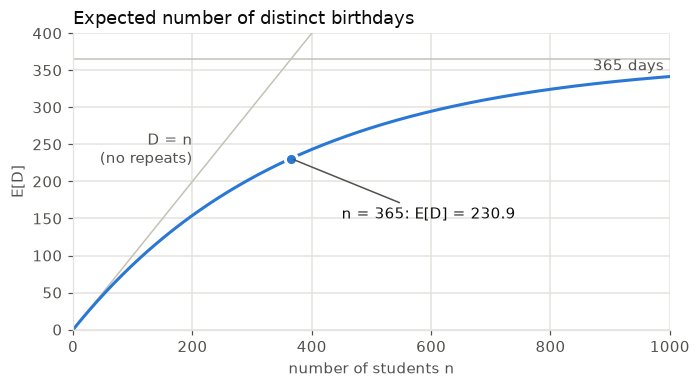

In [30]:
ns = np.arange(1, 1001)
ED_curve = DAYS * (1 - (364 / 365) ** ns)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ns[:400], ns[:400], color=FAINT, lw=1)
ax.axhline(DAYS, color=FAINT, lw=1)
ax.plot(ns, ED_curve, color=BLUE, lw=2)
ax.plot([365], [ED_curve[364]], "o", color=BLUE, ms=8, mec="white", mew=2)
ax.annotate(f"n = 365: E[D] = {ED_curve[364]:.1f}", xy=(365, ED_curve[364]), xytext=(450, 150),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.text(200, 225, "D = n\n(no repeats)", color=MUTED, ha="right")
ax.text(990, 350, "365 days", color=MUTED, ha="right")
ax.set(xlim=(0, 1000), ylim=(0, 400), xlabel="number of students n", ylabel="E[D]")
ax.set_title("Expected number of distinct birthdays", color=INK, loc="left")
plt.show()

## Common pitfalls

1. **Reversing a conditional without the prior.** $P(D \mid F_2) = 10\%$ but $P(F_2 \mid D) = 50\%$. With rare conditions the gap is dramatic: a test that catches 98% of cases can still leave most positive results false (exercises, Problem 5).
2. **Dropping a branch from the denominator.** In Bayes' rule, $P(F)$ must include the weight of *every* hypothesis in the partition. If the posteriors do not add to 1, a branch is missing.
3. **Mixing up PMF and CDF, or $<$ and $\le$.** $F(x) = P(X \le x)$ includes the jump at $x$, while $P(X < x)$ does not. $F$ is defined on all of $\mathbb{R}$ and is flat between the values of $X$.
4. **Expecting $E[X]$ to be a possible or typical value.** Three coins have $E[X] = 1.5$ heads.
5. **Pushing a nonlinear function through $E$.** $E[X^2] \ne (E[X])^2$ and $E[1/X] \ne 1/E[X]$ in general. Only affine maps satisfy $E[aX + b] = aE[X] + b$.
6. **Using a shortcut outside its assumptions.** The uniform and symmetry shortcuts fail for the first red queen. The tail-sum formula needs values in $\lbrace 0, 1, 2, \dots \rbrace$ and starts at $i = 1$.
7. **Thinking the indicator method needs independence.** It does not, because linearity always holds. But it gives only the mean of the count, not its distribution.

## Key takeaways

- **Total probability:** $P(D) = \sum_i P(F_i)\,P(D \mid F_i)$, a weighted average over a partition. A probability tree draws it: multiply along paths, add the leaves. Phones: $P(D) = 0.06$.
- **Bayes' rule:** $P(F_i \mid D) = P(F_i)\,P(D \mid F_i) / P(D)$, that is, prior times likelihood, normalized. Phones: $1/3, 1/2, 1/6$.
- A **random variable** attaches a number to each outcome. Its PMF gives $P(X = x)$; its CDF $F(x) = P(X \le x)$ is a staircase on all of $\mathbb{R}$ whose jumps are the PMF.
- **Expectation** $E[X] = \sum_x x \, p(x)$ is a constant that predicts long-run averages. Bernoulli: $E[X] = p$. Three coins: 1.5.
- **Tail sums:** for $X \in \lbrace 0, 1, 2, \dots \rbrace$, $E[X] = \sum_{i \ge 1} P(X \ge i)$. Queen of hearts: 26.5; first red queen: $53/3$.
- **LOTUS** $E[g(X)] = \sum_x g(x)\,p(x)$ and **linearity** $E[aX + bY + c] = aE[X] + bE[Y] + c$, which needs no independence.
- **Indicator method:** the mean of a count is the sum of the probabilities of its events. Distinct birthdays: $E[D] = 365\left(1 - (364/365)^n\right)$.
- Next session: variance and standard deviation, joint distributions, and covariance.